## Module 3: Computational Drug Discovery Project

**Team:** Sullivan Company, Team ___ *(add team member names)*

## Project Goal:

This project was carried out from the perspective of a Quantitative Systems Pharmacology team at the UVA Manning Institute for Biotechnology. The objective was to evaluate Cavalitide, a candidate GLP1 receptor agonist for weight loss, as a potential competitor to semaglutide (Ozempic and Wegovy). The work is organized into three tasks:
* **Task 1:** Fit a receptor-binding (pharmacodynamic) model to experimental Cavalitide binding data.
* **Task 2:** Simulate the pharmacokinetics of Cavalitide treatment.
* **Task 3:** Combine the two into a pharmacokinetic-pharmacodynamic (PKPD) model that predicts GLP1 receptor activity during treatment.

## Disease Background:

- **Prevalence & incidence:** About 40% of U.S. adults had obesity in 2021–2023 [1]. Worldwide, about 1 in 8 people were living with obesity in 2022 [2].
- **Diagnosis & prognosis:** Obesity is diagnosed mainly by BMI. It is a chronic disease that raises the risk of type 2 diabetes, cardiovascular disease and several cancers [2].
- **Biological mechanisms:** After a meal, the gut releases the incretin hormone GLP‑1, which binds the GLP‑1 receptor (GLP1R). This increases insulin release, slows stomach emptying and lowers appetite [3,4]. Native GLP‑1 is broken down within minutes, so drugs must last longer [4].
- **Standard of care:** Lifestyle change comes first, followed by medicines and bariatric surgery. Weekly injected semaglutide produced about 15% mean weight loss in the STEP‑1 trial [5].
- **Why better treatments are needed:** Semaglutide is expensive, insurance coverage is inconsistent, and GI side effects are common [5,6]. Much of the lost weight is regained after the drug is stopped [7]. Oral semaglutide must be taken while fasting, and only about 1% of it is absorbed [8]. Oral small-molecule GLP1R agonists such as orforglipron are in late-stage trials [9].

## Task 1: Fit a receptor binding model for Cavalitide:

The Lead Discovery group identified Cavalitide, a small molecule, and measured the fraction of active GLP1 receptors across a range of Cavalitide concentrations (cavalitide_data.csv). In this task, a pharmacodynamic model describing how native GLP1 and Cavalitide each bind and activate GLP1R is fitted to those data. The model and fitting code are adapted from the semaglutide analysis (fit_semaglutide_GLP1R.py, semaglutide_data.csv). The fitted Kd for Cavalitide is then compared with that of semaglutide.

### Model 
**Assumptions:**
1. GLP1 (L1) and the drug (L2) compete for one GLP1R binding site, and either one bound activates the receptor.
2. Binding is at equilibrium.
3. Free ligand concentrations do not change, because there is much more ligand than receptor.
4. Native GLP1 is fixed at the fasting level, 0.015 nM, as in `fit_semaglutide_GLP1R.py`.

From $R_T = R + RL_1 + RL_2$ with $K_{d1} = R L_1 / RL_1$ and $K_{d2} = R L_2/RL_2$:

$$F_{act} = \frac{RL_1 + RL_2}{R_T} = \frac{K_{d2}L_1 + K_{d1}L_2}{K_{d1}K_{d2} + K_{d2}L_1 + K_{d1}L_2}$$

**Parameters:** $K_{d1}$ = 0.17 nM for GLP1 (Lau et al. 2015 [10]). $K_{d2}$ is the fitted value.

### Fitting approach
We minimize the sum of squared errors, $SSE = \sum_i (y_i - F_{act}(L_{2,i};K_{d2}))^2$, in three ways:
1. **Brute force:** try 100 log-spaced values of Kd from 10⁻³ to 10² nM.
2. **Steepest-descent-type fit:** `scipy.optimize.curve_fit`.
3. **Hybrid:** brute force first, then curve_fit starting from the brute-force answer.

We fit **both** semaglutide and Cavalitide with the same code, so the two Kd values are directly comparable.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

def Fact(L1, L2, Kd1, Kd2):
    # Fractional GLP1R activation with two competing agonists L1 (GLP1) and L2 (drug)
    return (Kd2*L1 + Kd1*L2) / (Kd1*Kd2 + Kd2*L1 + Kd1*L2)

# Parameters [nM]
Kd1 = 0.17          # GLP1 at GLP1R (Lau et al. 2015)
L1_fast = 0.015     # fasting GLP1
L1_meal = 0.040      # GLP1 after a meal

In [2]:
def fit_Kd(csv_file, L1=L1_fast, Kd1=Kd1):
    # Fit Kd2 for a GLP1R agonist by brute force, curve_fit, and a hybrid of the two
    data = np.loadtxt(csv_file, delimiter=",", skiprows=1)
    L2_data, F_data = data[:, 0], data[:, 1]
    sse = lambda Kd2: np.sum((F_data - Fact(L1, L2_data, Kd1, Kd2))**2)

    # 1) Brute force over log-spaced candidates
    candidates = np.logspace(-3, 2, 100)
    sses = np.array([sse(k) for k in candidates])
    Kd_brute = candidates[np.argmin(sses)]

    # 2) curve_fit (gradient-based, like steepest descent) from a generic guess
    model = lambda L2, Kd2: Fact(L1, L2, Kd1, Kd2)
    popt, pcov = curve_fit(model, L2_data, F_data, p0=[0.1], bounds=(0, np.inf))
    Kd_cf, Kd_cf_se = popt[0], np.sqrt(pcov[0, 0])

    # 3) Hybrid: brute force gives the starting guess, curve_fit refines it
    popt_h, pcov_h = curve_fit(model, L2_data, F_data, p0=[Kd_brute], bounds=(0, np.inf))
    Kd_h = popt_h[0]

    R2 = 1 - sse(Kd_cf) / np.sum((F_data - F_data.mean())**2)
    return dict(L2=L2_data, F=F_data, cand=candidates, sses=sses,
                brute=Kd_brute, sse_brute=sse(Kd_brute),
                cf=Kd_cf, se=Kd_cf_se, sse_cf=sse(Kd_cf),
                hybrid=Kd_h, R2=R2)

fits = {"semaglutide": fit_Kd("semaglutide_data.csv"),
        "Cavalitide":  fit_Kd("cavalitide_data.csv")}

print(f"{'drug':<12}{'brute Kd':>10}{'SSE':>9}{'curve_fit Kd':>14}{'± SE':>8}{'SSE':>9}{'hybrid Kd':>11}{'R^2':>8}")
for name, f in fits.items():
    print(f"{name:<12}{f['brute']:>10.3f}{f['sse_brute']:>9.4f}{f['cf']:>14.3f}{f['se']:>8.3f}"
          f"{f['sse_cf']:>9.4f}{f['hybrid']:>11.3f}{f['R2']:>8.3f}")

Kd_sema = fits["semaglutide"]["cf"]
Kd_cav = fits["Cavalitide"]["cf"]
# 95% CI is about ±1.96 SE
lo, hi = Kd_cav - 1.96*fits["Cavalitide"]["se"], Kd_cav + 1.96*fits["Cavalitide"]["se"]
print(f"\nCavalitide Kd = {Kd_cav:.3f} nM (95% CI ~{lo:.3f}-{hi:.3f} nM)")
print(f"Semaglutide Kd = {Kd_sema:.3f} nM (literature value 0.38 nM)")
print(f"Cavalitide binds ~{Kd_sema/Kd_cav:.1f}x more tightly than semaglutide")

drug          brute Kd      SSE  curve_fit Kd    ± SE      SSE  hybrid Kd     R^2
semaglutide      0.335   0.0047         0.350   0.019   0.0044      0.350   0.997
Cavalitide       0.074   0.0054         0.077   0.005   0.0052      0.077   0.997

Cavalitide Kd = 0.077 nM (95% CI ~0.068-0.086 nM)
Semaglutide Kd = 0.350 nM (literature value 0.38 nM)
Cavalitide binds ~4.5x more tightly than semaglutide


### (b) Fit quality

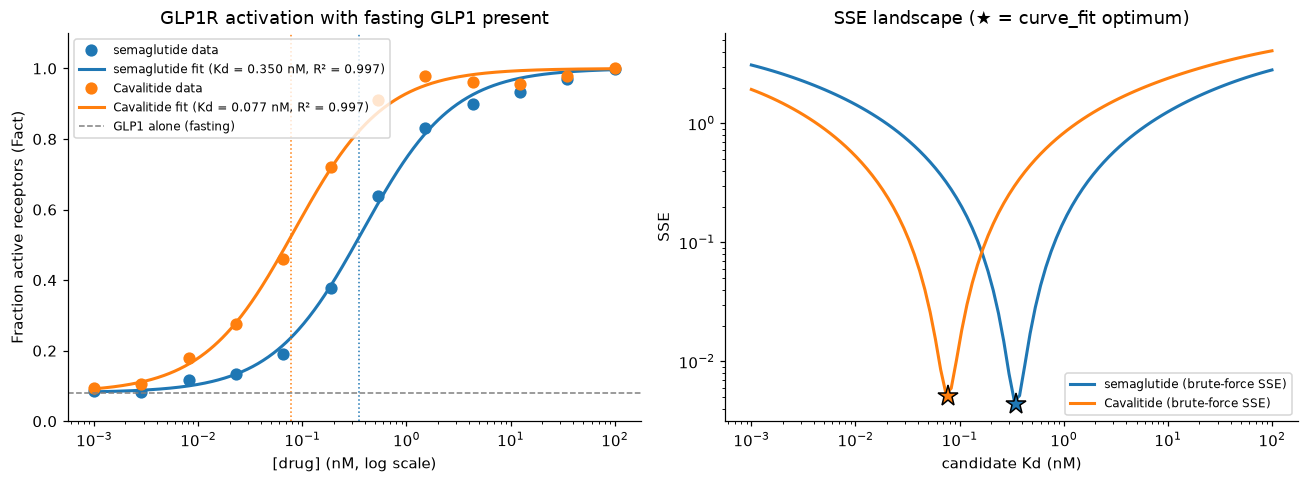

Cavalitide residuals: [ 0.003 -0.005  0.016 -0.003 -0.025  0.003  0.035  0.027 -0.022 -0.038
 -0.019  0.001]
max |residual| = 0.038


In [3]:
L2 = np.logspace(-3, 2, 500)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colors = {"semaglutide": "tab:blue", "Cavalitide": "tab:orange"}

ax = axes[0]
for name, f in fits.items():
    c = colors[name]
    ax.semilogx(f["L2"], f["F"], "o", c=c, ms=7, label=f"{name} data")
    ax.semilogx(L2, Fact(L1_fast, L2, Kd1, f["cf"]), "-", c=c, lw=2,
                label=f"{name} fit (Kd = {f['cf']:.3f} nM, R² = {f['R2']:.3f})")
    ax.axvline(f["cf"], ls=":", c=c, lw=1)
ax.axhline(Fact(L1_fast, 0, Kd1, 1), ls="--", c="gray", lw=1, label="GLP1 alone (fasting)")
ax.set_xlabel("[drug] (nM, log scale)")
ax.set_ylabel("Fraction active receptors (Fact)")
ax.set_ylim(0, 1.1)
ax.set_title("GLP1R activation with fasting GLP1 present")
ax.legend(fontsize=8, loc="upper left")

ax = axes[1]
for name, f in fits.items():
    ax.loglog(f["cand"], f["sses"], c=colors[name], lw=2, label=f"{name} (brute-force SSE)")
    ax.plot(f["cf"], f["sse_cf"], "*", c=colors[name], ms=14, mec="k")
ax.set_xlabel("candidate Kd (nM)")
ax.set_ylabel("SSE")
ax.set_title("SSE landscape (★ = curve_fit optimum)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Residuals check: no systematic trend means the model shape fits the data
f = fits["Cavalitide"]
res = f["F"] - Fact(L1_fast, f["L2"], Kd1, f["cf"])
print("Cavalitide residuals:", np.round(res, 3))
print(f"max |residual| = {np.abs(res).max():.3f}")

### (c) Interpretation of Kd

**Cavalitide Kd ≈ 0.077 nM**, compared with ≈ 0.35 nM for semaglutide fitted the same way (literature value 0.38 nM). All three methods agree, the SSE landscape has a single clear minimum, R² > 0.99, and the residuals are small with no trend. Kd is the concentration that occupies half of the receptors, so Cavalitide binds GLP1R about **4–5× more tightly** than semaglutide. It also binds more tightly than native GLP1 (0.17 nM) and liraglutide (0.11 nM).

**Advantages**
- It needs a lower concentration to activate the same fraction of receptors. This means a lower dose or a lower required oral bioavailability, which matters most for an oral drug that is poorly absorbed.
- Receptor activation stays high even when drug concentration drops between doses (see Task 3).
- As a small molecule, it could be cheaper to make than a peptide and could be given orally.

**Disadvantages / risks**
- A lower Kd means higher potency, not higher maximal effect. Both drugs reach Fact → 1. In this model, potency only shifts the curve to the left.
- Because it binds so tightly, the curve is steep in the sub-nM range. Small differences in exposure between patients could push the receptor to near-full activation. This could worsen dose-dependent GI side effects, so careful dose titration would be needed.
- Very tight binding can drive receptor internalization and desensitization. This equilibrium model does not include either effect.
- Kd alone does not determine clinical success. Blood protein binding, half-life, absorption and off-target effects (Tasks 2–3) matter as much. The comparison is also only valid if the assay conditions (fasting GLP1 = 0.015 nM) match how Cavalitide would actually be used.

## Task 2: Simulate the pharmacokinetics of Cavalitide treatment

Following the Task 1 results, this task supports the design of the Phase 1 clinical trial for the pill version of Cavalitide. The pharmacokinetic (PK) model is adapted from the semaglutide PK model `semaglutidePK.py` [12], which simulates Ozempic (subcutaneous injection once per week) and Wegovy (daily pill).

### PK model
The model tracks two quantities over time:

| Quantity | What it represents | How it changes |
|---|---|---|
| **Depot amount** $A_{depot}$ [mg] | Drug waiting to be absorbed: the subcutaneous depot for an injection, or the gut (oral) depot for a pill | Each dose adds $F_{available} \cdot D$. Drug leaves at the absorption rate $k_a$. |
| **Blood concentration** $C_c$ [mg/L] | Drug in the blood | Drug arrives from the depot at rate $k_a$ and is removed at the elimination rate $k_e$. |

$$\frac{dA_{depot}}{dt} = -k_a A_{depot}, \qquad \frac{dC_c}{dt} = \frac{k_a A_{depot}}{V} - k_e C_c$$

Blood concentration is converted to nM using the molecular weight ($C_c \cdot 10^{6} / MW$). Only the free fraction can bind GLP1R, so the quantity of interest is the **free blood concentration**, $F_{free} \cdot C_c$. The rest of the drug is bound to albumin [11,12].

**Assumptions**
1. The depot and the blood are each well mixed.
2. Absorption and elimination follow first-order kinetics (rate = rate constant × amount).
3. Each dose places the absorbed fraction, $F_{available} \cdot D$, into the depot at the time of dosing.
4. The description of Cavalitide specifies only its absorption rate ($k_a$ = 0.006 1/h). All of its other PK parameters are taken to be the same as the Wegovy pill.

**Parameters**

| Parameter | Ozempic | Wegovy | Cavalitide |
|---|---|---|---|
| Depot | subcutaneous | gut (oral) | gut (oral) |
| Bioavailability $F_{available}$ | 0.89 | 0.01 | 0.01 (as Wegovy) |
| Absorption rate $k_a$ [1/h] | 0.029 | 0.0029 | **0.006** |
| Dose $D$ [mg] | 2.0 | 25 | 25 (starting value, optimized in Task 2c) |
| Interval between doses [h] | 168 (weekly) | 24 (daily) | 24 (daily) |
| Number of doses | 8 | 100 | 100 |

Shared parameters: elimination rate $k_e$ = 0.0039 1/h, volume $V$ = 10.8 L, $MW$ = 4113.6 g/mol and $F_{free}$ = 0.01 [12].

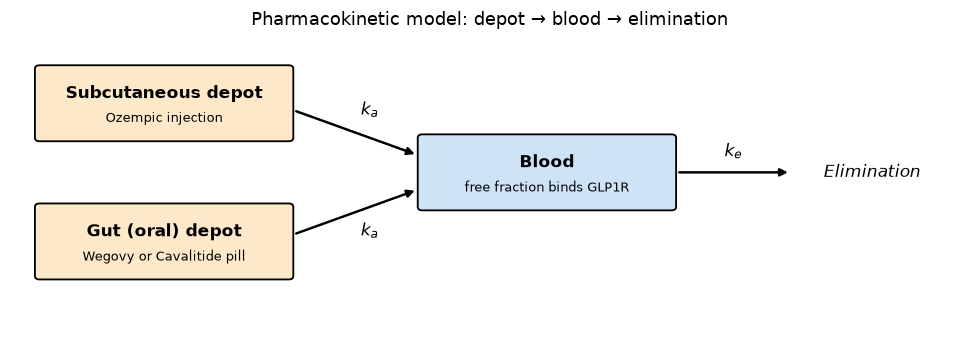

In [4]:
# Diagram of the PK model
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.set_xlim(0, 10); ax.set_ylim(0, 4.6); ax.axis("off")

def box(x, y, title, sub, color):
    ax.add_patch(FancyBboxPatch((x - 1.3, y - 0.5), 2.6, 1.0, boxstyle="round,pad=0.05",
                                fc=color, ec="k", lw=1.2))
    ax.text(x, y + 0.14, title, ha="center", va="center", fontsize=11, weight="bold")
    ax.text(x, y - 0.22, sub, ha="center", va="center", fontsize=8.5)

def arrow(x0, y0, x1, y1, label, lx, ly):
    ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle="-|>", lw=1.6, color="k"))
    ax.text(lx, ly, label, ha="center", va="center", fontsize=11)

box(1.6, 3.6, "Subcutaneous depot", "Ozempic injection", "#fde9c9")
box(1.6, 1.6, "Gut (oral) depot", "Wegovy or Cavalitide pill", "#fde9c9")
box(5.6, 2.6, "Blood", "free fraction binds GLP1R", "#cfe3f7")
ax.text(9.0, 2.6, "Elimination", ha="center", va="center", fontsize=11, style="italic")

arrow(2.95, 3.5, 4.25, 2.85, "$k_a$", 3.75, 3.5)
arrow(2.95, 1.7, 4.25, 2.35, "$k_a$", 3.75, 1.75)
arrow(6.95, 2.6, 8.15, 2.6, "$k_e$", 7.55, 2.9)
ax.set_title("Pharmacokinetic model: depot → blood → elimination", fontsize=12)
plt.tight_layout(); plt.show()

### a) Ozempic and Wegovy simulated with `scipy.integrate.solve_ivp`
The code below is `semaglutidePK.py` with the explicit Euler's method replaced by the built-in function `scipy.integrate.solve_ivp`. The original Euler loop is kept as an option so that the two methods can be compared. The first two plots reproduce the plots from `semaglutidePK.py` for each product. The third plot compares the predicted free blood concentration of Ozempic and Wegovy over the same 100 days.

product     free at steady state [nM]    min    max  days to 90%  max |solve_ivp - Euler| [nM]
Ozempic                         0.611  0.497  0.683         15.4                       2.4e-04


Wegovy                          0.599  0.599  0.599         47.9                       5.4e-05


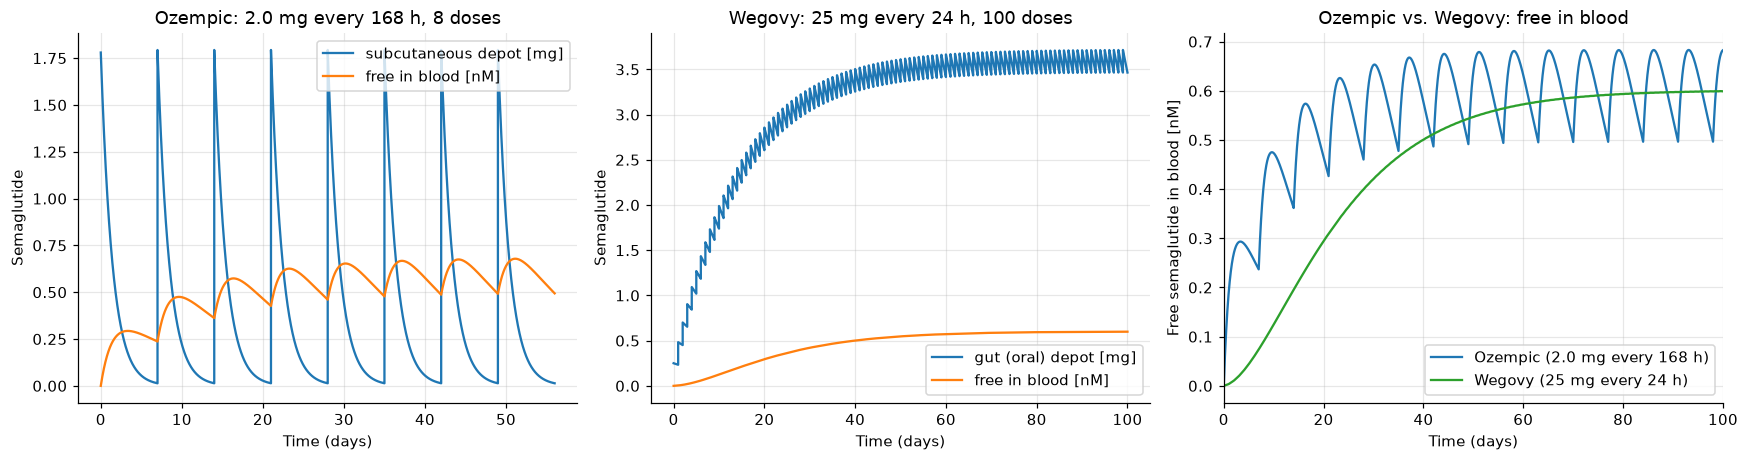

In [5]:
from scipy.integrate import solve_ivp

# product-specific parameters (from semaglutidePK.py)
products = {
    'Ozempic': dict(Favailable=0.89,   # bioavailability
                    ka=0.029,          # 1/h, absorption rate
                    D=2.0,             # mg per dose
                    interval=168,      # h between doses (weekly)
                    n_doses=8,         # number of doses
                    depot='subcutaneous'),
    'Wegovy':  dict(Favailable=0.01,
                    ka=0.0029,
                    D=25,              # mg
                    interval=24,       # h between doses (daily)
                    n_doses=100,
                    depot='gut (oral)'),
}

# shared model parameters
ke = 0.0039     # 1/h, elimination rate
V = 10.8        # L
MW = 4113.6     # g/mol
Ffree = 0.01    # rest of semaglutide bound to albumin
dt = 0.1        # h, spacing of the output time points

def ODEfunc(t, y, ka):
    Adepot, Cc = y
    dAdepot = -ka*Adepot             # Adepot: depot amount (mg)
    dCc = ka*Adepot/V - ke*Cc        # Cc: blood concentration (mg/L)
    return [dAdepot, dCc]

def simulate(p, D=None, interval=None, n_doses=None, method="solve_ivp"):
    # Repeated dosing every `interval` h. Returns time (h), depot amount (mg)
    # and blood concentration (nmol/L). D, interval and n_doses override the product values.
    D = p['D'] if D is None else D
    interval = p['interval'] if interval is None else interval
    n_doses = p['n_doses'] if n_doses is None else n_doses
    t_out, A_out, Cc_out = [], [], []
    y = np.array([0.0, 0.0])
    n_steps = int(round(interval / dt))
    for i in range(n_doses):
        y[0] += p['Favailable']*D            # absorbed fraction of dose enters the depot
        t0 = i * interval
        t_seg = t0 + dt * np.arange(n_steps + 1)
        if method == "solve_ivp":
            # built-in adaptive Runge-Kutta solver (replaces the explicit Euler loop)
            sol = solve_ivp(ODEfunc, (t_seg[0], t_seg[-1]), y, t_eval=t_seg, args=(p['ka'],),
                            rtol=1e-8, atol=1e-10)
            y_seg = sol.y
        else:
            # original explicit Euler: y[n+1] = y[n] + dt * f(t[n], y[n])
            y_seg = np.zeros((2, n_steps + 1))
            y_seg[:, 0] = y
            for n in range(n_steps):
                y_seg[:, n + 1] = y_seg[:, n] + dt * np.array(ODEfunc(t_seg[n], y_seg[:, n], p['ka']))
        t_out.append(t_seg); A_out.append(y_seg[0]); Cc_out.append(y_seg[1])
        y = y_seg[:, -1].copy()              # carry state into next interval
    t = np.concatenate(t_out)
    Cc_nM = np.concatenate(Cc_out) * 1e-3 / MW * 1e9
    return t, np.concatenate(A_out), Cc_nM

def steady_state(t, y, interval):
    # Mean, minimum and maximum of y over the last dosing interval
    last = t >= t[-1] - interval
    return y[last].mean(), y[last].min(), y[last].max()

def time_to_90(t, y, interval):
    # Days needed to first reach 90% of the steady-state mean
    return t[np.argmax(y >= 0.9*steady_state(t, y, interval)[0])] / 24

# --- run both products and plot them as in semaglutidePK.py ---
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, drug in zip(axes, ['Ozempic', 'Wegovy']):
    p = products[drug]
    t, Adepot, Cc = simulate(p)
    ax.plot(t/24, Adepot, label=f"{p['depot']} depot [mg]")
    ax.plot(t/24, Ffree*Cc, label="free in blood [nM]")
    ax.set_xlabel("Time (days)"); ax.set_ylabel("Semaglutide")
    ax.set_title(f"{drug}: {p['D']} mg every {p['interval']} h, {p['n_doses']} doses")
    ax.legend(); ax.grid(alpha=0.3)

# --- comparison of the two predicted profiles over the same 100 days ---
sim_colors = {'Ozempic': 'tab:blue', 'Wegovy': 'tab:green', 'Cavalitide': 'tab:orange'}
n_100d = {'Ozempic': 15, 'Wegovy': 100}      # doses needed to cover 100 days
ax = axes[2]
print(f"{'product':<10}{'free at steady state [nM]':>27}{'min':>7}{'max':>7}{'days to 90%':>13}{'max |solve_ivp - Euler| [nM]':>30}")
for drug in ['Ozempic', 'Wegovy']:
    p = products[drug]
    t, Adepot, Cc = simulate(p, n_doses=n_100d[drug])
    te, Ae, Cce = simulate(p, n_doses=n_100d[drug], method="euler")
    free = Ffree*Cc
    ax.plot(t/24, free, c=sim_colors[drug], label=f"{drug} ({p['D']} mg every {p['interval']} h)")
    m, lo, hi = steady_state(t, free, p['interval'])
    print(f"{drug:<10}{m:>27.3f}{lo:>7.3f}{hi:>7.3f}{time_to_90(t, free, p['interval']):>13.1f}"
          f"{np.abs(free - Ffree*Cce).max():>30.1e}")
ax.set_xlim(0, 100)
ax.set_xlabel("Time (days)"); ax.set_ylabel("Free semaglutide in blood [nM]")
ax.set_title("Ozempic vs. Wegovy: free in blood"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretation (a).**
- **Solver:** `solve_ivp` reproduces the Euler's method results. The largest difference in free blood concentration is about 0.0002 nM (less than 0.05%). `solve_ivp` chooses its own step size to meet an error tolerance, so it does not depend on a hand-picked step size.
- **Ozempic:** the free blood concentration rises and falls with each weekly injection. At steady state it averages about 0.61 nM and swings between about 0.50 and 0.68 nM. It reaches 90% of steady state after about 15 days.
- **Wegovy:** the free blood concentration is almost flat and settles at about 0.60 nM. It takes about 48 days to reach 90% of steady state, because its absorption rate (0.0029 1/h) is slower than the elimination rate (0.0039 1/h), so drug builds up slowly in the gut (oral) depot.
- **Comparison:** both products reach nearly the same steady-state free blood concentration. This is because the absorbed dose per hour is nearly the same: $F_{available} \cdot D / \text{interval}$ = 0.89 × 2 mg / 168 h ≈ 0.0106 mg/h for Ozempic and 0.01 × 25 mg / 24 h ≈ 0.0104 mg/h for Wegovy. The pill needs a much larger dose because only 1% of it is absorbed.

### b) Cavalitide (daily pill) with an increased absorption rate
Cavalitide is added to the model as a daily pill with an increased absorption rate, $k_a$ = 0.006 1/h. The plots show the depot amount and free blood concentration in the same format as above, and the Cavalitide blood concentration over time compared with Wegovy.

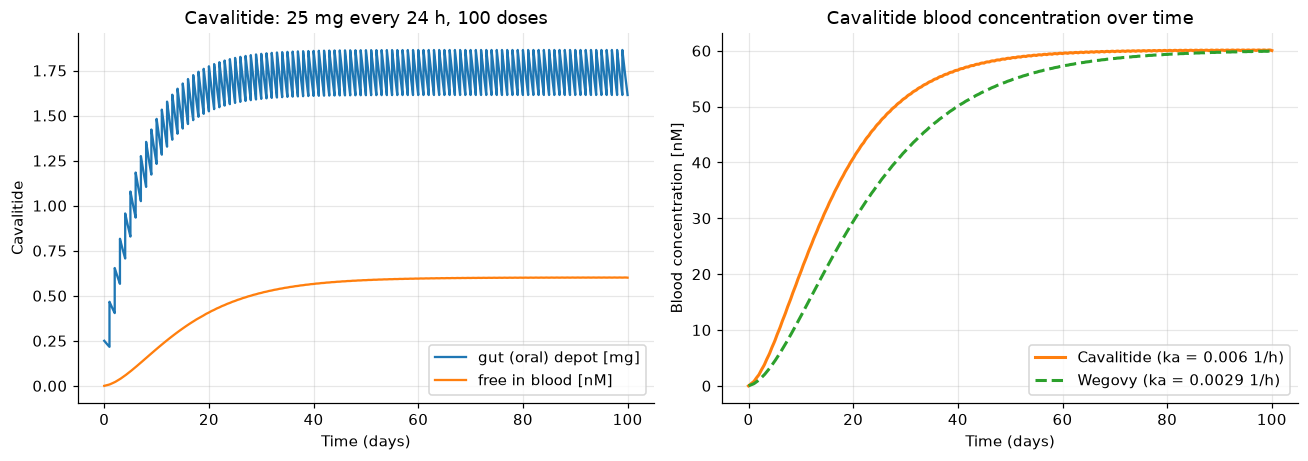

product       blood at steady state [nM]  free [nM]  peak/trough  days to 90%
Cavalitide                          60.1      0.601        1.002         34.1
Wegovy                              59.9      0.599        1.001         47.9


In [6]:
# Cavalitide (daily pill): same as the Wegovy pill except for the increased absorption rate
products['Cavalitide'] = dict(Favailable=0.01,
                              ka=0.006,          # 1/h, increased absorption rate
                              D=25,              # mg
                              interval=24,       # h between doses (daily)
                              n_doses=100,
                              depot='gut (oral)')

p = products['Cavalitide']
t_cav, A_cav, Cc_cav = simulate(p)
t_weg, A_weg, Cc_weg = simulate(products['Wegovy'])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]
ax.plot(t_cav/24, A_cav, label=f"{p['depot']} depot [mg]")
ax.plot(t_cav/24, Ffree*Cc_cav, label="free in blood [nM]")
ax.set_xlabel("Time (days)"); ax.set_ylabel("Cavalitide")
ax.set_title(f"Cavalitide: {p['D']} mg every {p['interval']} h, {p['n_doses']} doses")
ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(t_cav/24, Cc_cav, c=sim_colors['Cavalitide'], lw=2, label="Cavalitide (ka = 0.006 1/h)")
ax.plot(t_weg/24, Cc_weg, c=sim_colors['Wegovy'], lw=2, ls="--", label="Wegovy (ka = 0.0029 1/h)")
ax.set_xlabel("Time (days)"); ax.set_ylabel("Blood concentration [nM]")
ax.set_title("Cavalitide blood concentration over time")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

print(f"{'product':<12}{'blood at steady state [nM]':>28}{'free [nM]':>11}{'peak/trough':>13}{'days to 90%':>13}")
for drug, (t, Cc) in {'Cavalitide': (t_cav, Cc_cav), 'Wegovy': (t_weg, Cc_weg)}.items():
    m, lo, hi = steady_state(t, Cc, 24)
    print(f"{drug:<12}{m:>28.1f}{Ffree*m:>11.3f}{hi/lo:>13.3f}{time_to_90(t, Cc, 24):>13.1f}")

**Interpretation (b).** At the same 25 mg daily dose, Cavalitide reaches the same steady-state blood concentration as Wegovy (about 60 nM in blood, 0.60 nM free). The absorption rate does not change the steady-state level, which is set by $F_{available} \cdot D / (k_e \cdot V \cdot \text{interval})$. The increased absorption rate changes how fast that level is reached: Cavalitide reaches 90% of steady state in about **34 days**, compared with about 48 days for Wegovy. The blood concentration remains almost flat within each day (peak-to-trough ratio 1.002).

### c) Optimizing the dosing strategy for a steady-state free blood concentration of 0.5 nM
At 25 mg per day, Cavalitide settles at about 0.60 nM free in blood, which is above the 0.5 nM target. The dose $D$ is adjusted, with all other parameters unchanged, until the steady-state free blood concentration is close to 0.5 nM.

D [mg/day]    steady-state free in blood [nM]
25                                      0.601
23                                      0.553
22                                      0.529
21                                      0.505
20                                      0.481


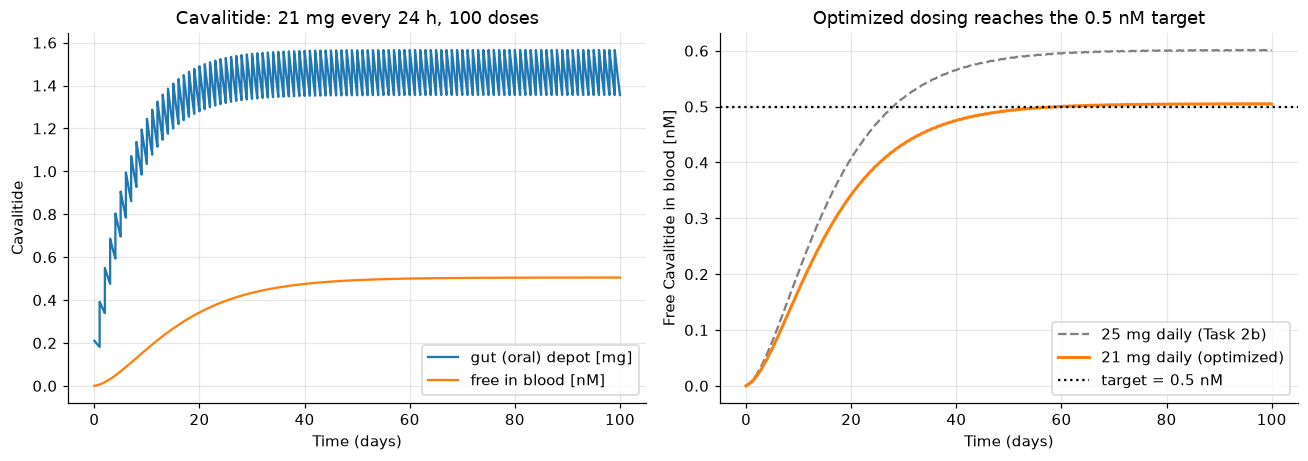


Selected dose: 21 mg once daily -> steady-state free in blood = 0.505 nM (range 0.504-0.505 nM), 90% of steady state reached after 34 days


In [7]:
target_free = 0.5     # nM, desired steady-state free blood concentration

# Adjust the dose D (all other parameters unchanged) and check the steady-state free concentration
print(f"{'D [mg/day]':<12}{'steady-state free in blood [nM]':>33}")
for D_try in [25, 23, 22, 21, 20]:
    t, A, Cc = simulate(products['Cavalitide'], D=D_try)
    print(f"{D_try:<12}{steady_state(t, Ffree*Cc, 24)[0]:>33.3f}")

D_phase1 = 21         # mg/day, selected Phase 1 dose
t_p1, A_p1, Cc_p1 = simulate(products['Cavalitide'], D=D_phase1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]
ax.plot(t_p1/24, A_p1, label="gut (oral) depot [mg]")
ax.plot(t_p1/24, Ffree*Cc_p1, label="free in blood [nM]")
ax.set_xlabel("Time (days)"); ax.set_ylabel("Cavalitide")
ax.set_title(f"Cavalitide: {D_phase1} mg every 24 h, 100 doses")
ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(t_cav/24, Ffree*Cc_cav, c="gray", ls="--", label="25 mg daily (Task 2b)")
ax.plot(t_p1/24, Ffree*Cc_p1, c=sim_colors['Cavalitide'], lw=2, label=f"{D_phase1} mg daily (optimized)")
ax.axhline(target_free, c="k", ls=":", label=f"target = {target_free} nM")
ax.set_xlabel("Time (days)"); ax.set_ylabel("Free Cavalitide in blood [nM]")
ax.set_title("Optimized dosing reaches the 0.5 nM target")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

m, lo, hi = steady_state(t_p1, Ffree*Cc_p1, 24)
print(f"\nSelected dose: {D_phase1} mg once daily -> steady-state free in blood = {m:.3f} nM "
      f"(range {lo:.3f}-{hi:.3f} nM), 90% of steady state reached after {time_to_90(t_p1, Ffree*Cc_p1, 24):.0f} days")

**What was changed and why (c).** One dosing parameter was changed: the dose $D$ was reduced from **25 mg to 21 mg once daily**. This gives a steady-state free blood concentration of 0.505 nM.

- **Why the dose:** the steady-state concentration is directly proportional to the dose, so the dose is the most direct way to set it. The 25 mg dose overshoots the 0.5 nM target by about 20%.
- **Why a lower dose is possible:** the increased absorption rate does not raise the steady-state level, but it does bring the drug to that level faster (about 34 days, compared with about 48 days for Wegovy). The target can therefore be reached sooner than with Wegovy while using 16% less drug per pill. A lower dose should also reduce cost and dose-related side effects.
- **What was kept:** the interval stays at 24 h. A once-daily pill is simple for patients, and it keeps the blood concentration almost flat. The number of doses stays at 100 so that the simulation covers the time needed to reach steady state.

## Task 3: Simulate a combined pharmacokinetics-pharmacodynamics (PKPD) model that predicts GLP1 receptor activity during treatment

After the Phase 1 clinical trial achieved the desired 0.5 nM free concentration of Cavalitide, the dosing is customized further for the Phase 2 clinical trial, where the focus is efficacy. The PK model (Task 2) and the PD model (Task 1) are combined to predict how the fraction of activated receptors changes over time.

### a) Combined PKPD model: fraction of active GLP1R over the first 100 days
The ligand-receptor model from Task 1 is embedded into the Cavalitide PK model. The free Cavalitide concentration in blood from the PK model is the ligand concentration $L_2$ in the receptor model, with the Kd for Cavalitide fitted in Task 1:

$$F_{act}(t) = \frac{K_{d2}L_1 + K_{d1}L_2(t)}{K_{d1}K_{d2} + K_{d2}L_1 + K_{d1}L_2(t)}, \qquad L_2(t) = F_{free} \cdot C_c(t)$$

Native GLP1 ($L_1$) is held at its fasting level of 0.015 nM with $K_{d1}$ = 0.17 nM, as in Task 1. Binding is assumed to reach equilibrium quickly compared with the PK. The simulation uses the optimized Phase 1 dosing from Task 2c (21 mg once daily). The same model is provided as the script `cavalitidePKPD.py`.

Kd of Cavalitide from Task 1 = 0.077 nM


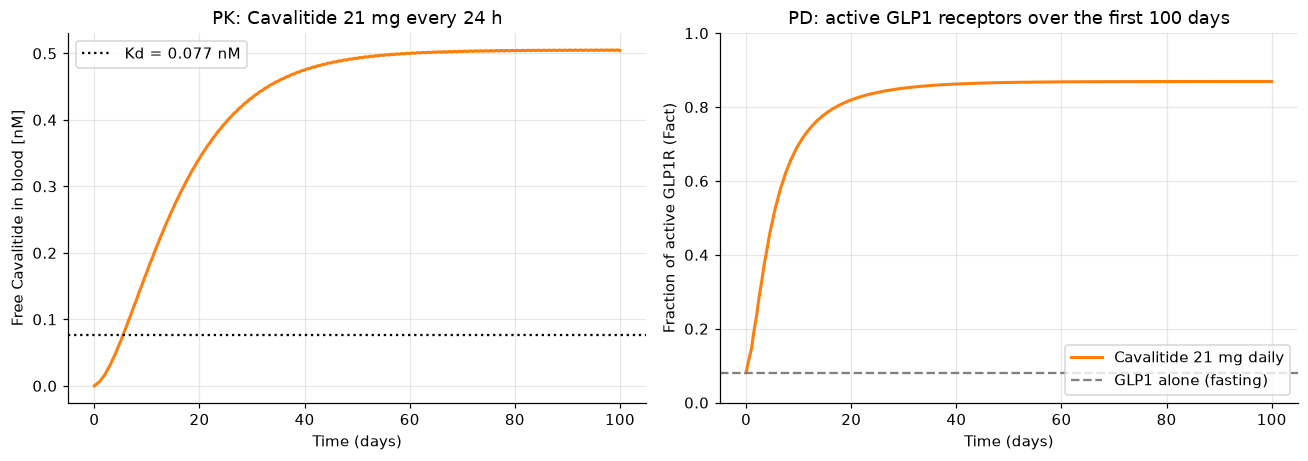

day   1: Fact = 0.143
day   7: Fact = 0.598
day  14: Fact = 0.769
day  30: Fact = 0.851
day  60: Fact = 0.868
day 100: Fact = 0.869
Steady state (day 100): Fact = 0.869; 90% of the steady-state value is reached after 15 days


In [8]:
# Combined PKPD model: PK (Task 2) -> free Cavalitide in blood -> ligand-receptor model (Task 1)
L1 = L1_fast                    # nM, native GLP1 (fasting), as in the Task 1 fit
print(f"Kd of Cavalitide from Task 1 = {Kd_cav:.3f} nM")

def simulate_PKPD(p, Kd2, D=None, n_doses=None):
    # Returns time (h), free drug in blood (nM) and fraction of active GLP1R
    t, Adepot, Cc = simulate(p, D=D, n_doses=n_doses)
    L2 = Ffree*Cc                              # free drug is the ligand
    return t, L2, Fact(L1, L2, Kd1, Kd2)

t_pd, L2_pd, Fact_pd = simulate_PKPD(products['Cavalitide'], Kd_cav, D=D_phase1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
axes[0].plot(t_pd/24, L2_pd, c=sim_colors['Cavalitide'], lw=2)
axes[0].axhline(Kd_cav, c="k", ls=":", label=f"Kd = {Kd_cav:.3f} nM")
axes[0].set_xlabel("Time (days)"); axes[0].set_ylabel("Free Cavalitide in blood [nM]")
axes[0].set_title(f"PK: Cavalitide {D_phase1} mg every 24 h"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(t_pd/24, Fact_pd, c=sim_colors['Cavalitide'], lw=2, label=f"Cavalitide {D_phase1} mg daily")
axes[1].axhline(Fact(L1, 0, Kd1, Kd_cav), c="gray", ls="--", label="GLP1 alone (fasting)")
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("Time (days)"); axes[1].set_ylabel("Fraction of active GLP1R (Fact)")
axes[1].set_title("PD: active GLP1 receptors over the first 100 days"); axes[1].legend(loc="lower right"); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

m, lo, hi = steady_state(t_pd, Fact_pd, 24)
for day in (1, 7, 14, 30, 60, 100):
    print(f"day {day:>3}: Fact = {Fact_pd[np.argmin(np.abs(t_pd - day*24))]:.3f}")
print(f"Steady state (day 100): Fact = {m:.3f}; 90% of the steady-state value is reached after "
      f"{time_to_90(t_pd, Fact_pd, 24):.0f} days")

**Interpretation (a).** With GLP1 alone, about 8% of GLP1 receptors are active. During Cavalitide treatment at 21 mg once daily, the fraction of active GLP1R rises to about 0.60 after one week and 0.77 after two weeks. It levels off at about **0.87 at steady state**. Receptor activation approaches its steady state faster than the blood concentration does (90% of the steady-state value after about 15 days, compared with about 34 days for concentration). This is because the steady-state free concentration (0.505 nM) is about 6.6 times the Kd of Cavalitide (0.077 nM), so the receptors are already close to saturated before the concentration stops rising.

### b) Optimizing the dosing strategy for about 90% active GLP1 receptors at steady state
The dose $D$ is adjusted again until the fraction of active GLP1R at steady state (around 100 days) is close to 90%.

D [mg/day]    free in blood [nM]  Fact at steady state
21                         0.505                 0.869
25                         0.601                 0.888
28                         0.673                 0.898
28.5                       0.685                 0.900
30                         0.721                 0.904
40                         0.962                 0.926


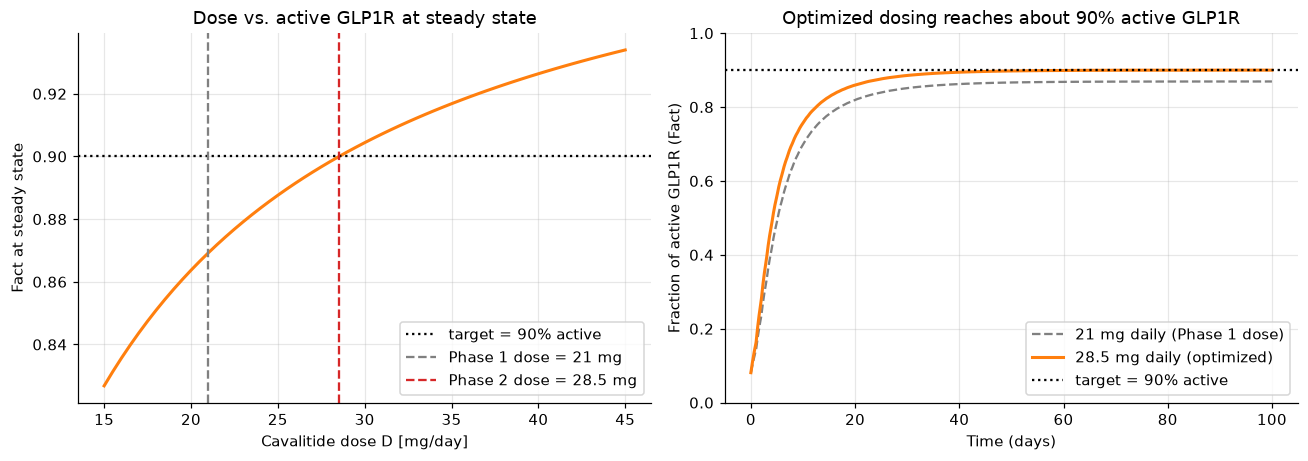


Selected dose: 28.5 mg once daily -> Fact at steady state = 0.900 (range 0.900-0.900); free in blood = 0.685 nM
Days to reach Fact = 0.80: 12 (optimized) vs. 17 (Phase 1 dose)


In [9]:
target_Fact = 0.90    # desired fraction of active GLP1R at steady state

# Adjust the dose D and check the steady-state fraction of active receptors
doses = np.arange(15, 45.5, 0.5)
Fact_ss = np.array([steady_state(*simulate_PKPD(products['Cavalitide'], Kd_cav, D=D_try)[::2], 24)[0]
                    for D_try in doses])
D_phase2 = doses[np.argmin(np.abs(Fact_ss - target_Fact))]

print(f"{'D [mg/day]':<12}{'free in blood [nM]':>20}{'Fact at steady state':>22}")
for D_try in [D_phase1, 25, 28, D_phase2, 30, 40]:
    t, L2, Fa = simulate_PKPD(products['Cavalitide'], Kd_cav, D=D_try)
    print(f"{D_try:<12}{steady_state(t, L2, 24)[0]:>20.3f}{steady_state(t, Fa, 24)[0]:>22.3f}")

t_p2, L2_p2, Fact_p2 = simulate_PKPD(products['Cavalitide'], Kd_cav, D=D_phase2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
ax = axes[0]
ax.plot(doses, Fact_ss, c=sim_colors['Cavalitide'], lw=2)
ax.axhline(target_Fact, c="k", ls=":", label="target = 90% active")
ax.axvline(D_phase1, c="gray", ls="--", label=f"Phase 1 dose = {D_phase1} mg")
ax.axvline(D_phase2, c="tab:red", ls="--", label=f"Phase 2 dose = {D_phase2} mg")
ax.set_xlabel("Cavalitide dose D [mg/day]"); ax.set_ylabel("Fact at steady state")
ax.set_title("Dose vs. active GLP1R at steady state"); ax.legend(); ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(t_pd/24, Fact_pd, c="gray", ls="--", label=f"{D_phase1} mg daily (Phase 1 dose)")
ax.plot(t_p2/24, Fact_p2, c=sim_colors['Cavalitide'], lw=2, label=f"{D_phase2} mg daily (optimized)")
ax.axhline(target_Fact, c="k", ls=":", label="target = 90% active")
ax.set_ylim(0, 1)
ax.set_xlabel("Time (days)"); ax.set_ylabel("Fraction of active GLP1R (Fact)")
ax.set_title("Optimized dosing reaches about 90% active GLP1R"); ax.legend(loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

m, lo, hi = steady_state(t_p2, Fact_p2, 24)
print(f"\nSelected dose: {D_phase2} mg once daily -> Fact at steady state = {m:.3f} "
      f"(range {lo:.3f}-{hi:.3f}); free in blood = {steady_state(t_p2, L2_p2, 24)[0]:.3f} nM")
print(f"Days to reach Fact = 0.80: {t_p2[np.argmax(Fact_p2 >= 0.80)]/24:.0f} (optimized) "
      f"vs. {t_pd[np.argmax(Fact_pd >= 0.80)]/24:.0f} (Phase 1 dose)")

**Which dosing parameter was adjusted (b).** One dosing parameter was adjusted: the dose $D$ was increased from **21 mg to 28.5 mg once daily**. The interval (24 h) and the number of doses (100) were not changed. The steady-state free blood concentration rises from 0.505 nM to 0.685 nM, and the fraction of active GLP1R at steady state rises from 0.87 to **0.90**.

**Interpretation of the clinical benefits.**
- **Greater expected efficacy:** GLP1R activation drives the effects on appetite and insulin release, so a higher fraction of active receptors is expected to give a stronger weight-loss effect. This is the purpose of a Phase 2 clinical trial focused on efficacy.
- **Faster onset:** the fraction of active receptors passes 0.80 after about 12 days, compared with about 17 days at the Phase 1 dose.
- **Steady effect:** the once-daily pill keeps receptor activation essentially constant at steady state, with no weekly peaks and troughs.
- **A sensible stopping point:** the dose–response curve flattens as the receptors saturate. Raising the dose by 36% (21 → 28.5 mg) adds about 3 percentage points of receptor activation, and raising it further to 40 mg adds only about 2.5 more. Pushing well beyond 90% would therefore add drug exposure, cost and likely dose-related side effects (such as nausea) for little additional receptor activation.

### Comparison with semaglutide
To support the Conclusions, the same PKPD model is run for Ozempic and Wegovy at their standard dosing, using the Kd for semaglutide fitted in Task 1 (0.35 nM).

treatment                           Fact at steady state    min    max  days to Fact = 0.5
Ozempic (2.0 mg weekly, injected)                  0.646  0.601  0.671                 7.4
Wegovy (25 mg daily, pill)                         0.643  0.643  0.643                21.7
Cavalitide (28.5 mg daily, pill)                   0.900  0.900  0.900                 4.2


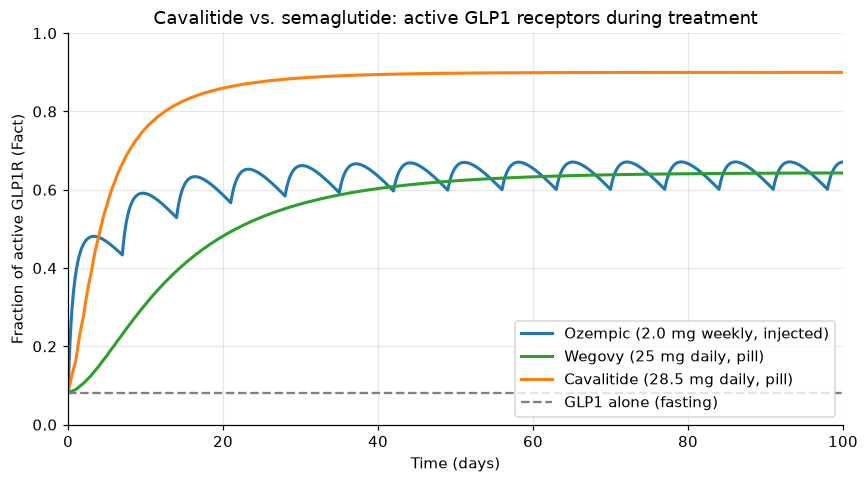

In [10]:
# Comparison with semaglutide: same PKPD model, using the semaglutide Kd fitted in Task 1
fig, ax = plt.subplots(figsize=(8, 4.5))
print(f"{'treatment':<34}{'Fact at steady state':>22}{'min':>7}{'max':>7}{'days to Fact = 0.5':>20}")
runs = [("Ozempic (2.0 mg weekly, injected)", 'Ozempic', Kd_sema, None, 15),
        ("Wegovy (25 mg daily, pill)", 'Wegovy', Kd_sema, None, 100),
        (f"Cavalitide ({D_phase2} mg daily, pill)", 'Cavalitide', Kd_cav, D_phase2, 100)]
for label, drug, Kd2, D_run, n in runs:
    p = products[drug]
    t, L2, Fa = simulate_PKPD(p, Kd2, D=D_run, n_doses=n)
    ax.plot(t/24, Fa, c=sim_colors[drug], lw=2, label=label)
    m, lo, hi = steady_state(t, Fa, p['interval'])
    print(f"{label:<34}{m:>22.3f}{lo:>7.3f}{hi:>7.3f}{t[np.argmax(Fa >= 0.5)]/24:>20.1f}")
ax.axhline(Fact(L1, 0, Kd1, Kd_cav), c="gray", ls="--", label="GLP1 alone (fasting)")
ax.set_xlim(0, 100); ax.set_ylim(0, 1)
ax.set_xlabel("Time (days)"); ax.set_ylabel("Fraction of active GLP1R (Fact)")
ax.set_title("Cavalitide vs. semaglutide: active GLP1 receptors during treatment")
ax.legend(loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

At steady state, Ozempic and Wegovy both activate about 64–65% of GLP1 receptors, while Cavalitide at 28.5 mg once daily activates about 90%. All three treatments reach a similar free blood concentration (0.6–0.7 nM), so the difference comes mainly from the lower Kd of Cavalitide. Cavalitide also passes 50% active receptors sooner (about 4 days, compared with about 7 days for Ozempic and 22 days for Wegovy).

## Conclusions:

- **Pharmacodynamics (Task 1):** Cavalitide binds GLP1R about **4.5 times more tightly** than semaglutide (Kd ≈ 0.077 nM vs. 0.35 nM; fit R² > 0.99). Less free drug is therefore needed to activate the same fraction of receptors.
- **Pharmacokinetics (Task 2):** as a daily pill with an increased absorption rate ($k_a$ = 0.006 1/h), Cavalitide reaches steady state faster than the Wegovy pill (about 34 vs. 48 days to 90% of steady state) and keeps an almost flat blood concentration. A dose of 21 mg once daily gives the Phase 1 target of 0.5 nM free in blood.
- **PKPD (Task 3):** at 28.5 mg once daily, Cavalitide activates about **90%** of GLP1 receptors at steady state. Ozempic (2 mg weekly) and Wegovy (25 mg daily) each activate about 64–65% in the same model.
- **vs. oral semaglutide (Wegovy):** at a similar daily pill dose (28.5 mg vs. 25 mg), Cavalitide is predicted to give much higher receptor activation and to reach it sooner. Both pills give a steady, flat effect.
- **vs. injected semaglutide (Ozempic):** Cavalitide is predicted to give higher receptor activation without injections and without the weekly rise and fall seen with Ozempic (Fact between about 0.60 and 0.67 each week).
- **Overall:** these analyses suggest that Cavalitide has strong potential to compete with both oral and injected semaglutide. The prediction rests on Cavalitide sharing the bioavailability, elimination rate, volume and free fraction of semaglutide, which must be confirmed in the Phase 1 clinical trial.

## Limitations and Future Work:

**Limitations**
- **Cavalitide PK parameters:** only the absorption rate of Cavalitide was specified. Its bioavailability, elimination rate, volume, free fraction and molecular weight were taken from semaglutide. Cavalitide is a small molecule, so these values are likely to differ. The molecular weight and free fraction directly change the predicted free blood concentration in nM.
- **Simple PK model:** the model has one depot and one blood compartment. It does not include a peripheral compartment, food effects on absorption or variability between patients. Oral absorption is described by a single first-order rate.
- **Equilibrium binding:** the PD model ignores binding and unbinding kinetics, receptor internalization, desensitization and downstream signaling. It predicts receptor activation, not weight loss.
- **Full agonist assumption:** any bound receptor is assumed to be fully active. Cavalitide could be a partial agonist.
- **Single binding dataset:** the Kd fit uses one curve at fasting GLP1 with no replicates, so experimental variability cannot be estimated. Native GLP1 is held constant even though it rises after a meal.
- **Efficacy vs. safety:** the dosing was optimized for receptor activation only. Side effects, which also increase with dose, were not modeled.

**Future work**
- Measure the bioavailability, elimination rate, volume and albumin binding of Cavalitide in the Phase 1 clinical trial, then refit the PK model to the measured blood concentrations.
- Repeat the binding experiment with replicates and at after-meal GLP1 levels, and report confidence intervals for Kd.
- Let native GLP1 vary with meals in the PKPD model.
- Add variability between patients to predict the range of responses and to choose a dose-escalation schedule.
- Link the fraction of active GLP1R to weight loss using clinical trial data, so that Cavalitide and semaglutide can be compared on clinical outcomes.

## AI Usage Statement:
We used Claude Code (Anthropic) to help draft this notebook. It adapted `fit_semaglutide_GLP1R.py` into a reusable fitting function with a brute-force, `curve_fit` and hybrid fit and a residual check. It adapted `semaglutidePK.py` to use `scipy.integrate.solve_ivp`, added Cavalitide, built the combined PKPD model (`cavalitidePK.py`, `cavalitidePKPD.py`) and drafted the markdown text. We checked the fitted Kd against our own run of the original semaglutide fitting script, confirmed that the `solve_ivp` results match the Euler's method results from `semaglutidePK.py`, and reviewed all citations.

## GitHub Repository Link:
https://github.com/zvCecilia/BME2315_Module3

The repository contains this notebook, the binding data (`cavalitide_data.csv`, `semaglutide_data.csv`), the PK and PKPD scripts (`semaglutidePK.py`, `cavalitidePK.py`, `cavalitidePKPD.py`) and the supporting analysis scripts (`fit_semaglutide_GLP1R.py`, `GLP1_GLP1R.py`, `ligand_receptor.py`).

## References:
1. Emmerich SD, Fryar CD, Stierman B, Ogden CL. *Obesity and Severe Obesity Prevalence in Adults: United States, August 2021–August 2023.* NCHS Data Brief No. 508, 2024. https://www.cdc.gov/nchs/products/databriefs/db508.htm
2. World Health Organization. *Obesity and overweight* fact sheet, 2024/2025. https://www.who.int/news-room/fact-sheets/detail/obesity-and-overweight
3. Seino Y, Fukushima M, Yabe D. GIP and GLP-1, the two incretin hormones: similarities and differences. *J Diabetes Investig.* 2010;1(1-2):8–23.
4. Müller TD et al. / Tschöp MH et al. incretin pharmacology reviews, *Diabetologia* 2023. https://pubmed.ncbi.nlm.nih.gov/37209227/
5. Wilding JPH et al. Once-weekly semaglutide in adults with overweight or obesity (STEP 1). *N Engl J Med.* 2021;384:989–1002.
6. Novo Nordisk. WEGOVY (semaglutide) injection, U.S. Prescribing Information (Clinical Pharmacology §12.3).
7. Wilding JPH et al. Weight regain and cardiometabolic effects after withdrawal of semaglutide: the STEP 1 trial extension. *Diabetes Obes Metab.* 2022;24:1553–1564.
8. Novo Nordisk. RYBELSUS (oral semaglutide) tablets, U.S. Prescribing Information (Dosage & Administration; Clinical Pharmacology §12.3).
9. Wharton S et al. Orforglipron, an oral small-molecule GLP-1 receptor agonist, in adults with obesity. *N Engl J Med.* 2025 (ATTAIN-1); and Pratt E et al. orforglipron Phase 1 PK, *Diabetes Obes Metab.* 2023.
10. Lau J et al. Discovery of the once-weekly GLP-1 analogue semaglutide. *J Med Chem.* 2015;58(18):7370–7380. (Kd values)
11. Hall S et al. Pharmacokinetics of semaglutide (clinical pharmacology review). *Clin Pharmacokinet.* 2018 / Overgaard RV et al. 2021.
12. Saucerman J. *Computational Drug Discovery: GLP1R pharmacodynamic and pharmacokinetic modeling materials.* University of Virginia, Department of Biomedical Engineering, 2026. Includes the semaglutide PK model and parameters (`semaglutidePK.py`), the Cavalitide absorption rate, and the scripts `ligand_receptor.py`, `GLP1_GLP1R.py` and `fit_semaglutide_GLP1R.py`.

## Team Notes:
- Task 1 complete: Cavalitide Kd ≈ 0.077 nM; semaglutide refit ≈ 0.35 nM (vs. 0.38 nM literature).
- Task 2 complete: `solve_ivp` replaces Euler's method; Cavalitide (ka = 0.006 1/h) reaches 0.5 nM free in blood at 21 mg once daily.
- Task 3 complete: 28.5 mg once daily gives about 90% active GLP1R at steady state.
- TODO: add team names, confirm references, finalize the 11/17 presentation.

## Questions for the TA:
1. Cavalitide is described as a small molecule. Should it use the molecular weight, bioavailability and free fraction of semaglutide, as assumed here, or different values?
2. For Tasks 2c and 3b, is the dose the expected parameter to adjust, or should the interval between doses also be changed?